In [1]:
#Downloading data set from nasa API


import requests
import pandas as pd
import time
from pathlib import Path


START = "20200528"
END = "20250427"



parameters = [
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "RH2M",
    "PRECTOTCORR",
    "WS10M",
    "WS50M",
    "WD10M",
    "ALLSKY_SFC_SW_DWN",
    "PS",
    "QV2M",
    "CLOUD_AMT"
]


# ==========================================
# 3. ALL 28 STATES + 8 UNION TERRITORIES
# Representative coordinates
# ==========================================


locations = {
    "Andhra Pradesh": (15.9129, 79.7400),
    "Arunachal Pradesh": (28.2180, 94.7278),
    "Assam": (26.2006, 92.9376),
    "Bihar": (25.0961, 85.3131),
    "Chhattisgarh": (21.2787, 81.8661),
    "Goa": (15.2993, 74.1240),
    "Gujarat": (22.2587, 71.1924),
    "Haryana": (29.0588, 76.0856),
    "Himachal Pradesh": (31.1048, 77.1734),
    "Jharkhand": (23.6102, 85.2799),
    "Karnataka": (15.3173, 75.7139),
    "Kerala": (10.8505, 76.2711),
    "Madhya Pradesh": (22.9734, 78.6569),
    "Maharashtra": (19.7515, 75.7139),
    "Manipur": (24.6637, 93.9063),
    "Meghalaya": (25.4670, 91.3662),
    "Mizoram": (23.1645, 92.9376),
    "Nagaland": (26.1584, 94.5624),
    "Odisha": (20.9517, 85.0985),
    "Punjab": (31.1471, 75.3412),
    "Rajasthan": (27.0238, 74.2179),
    "Sikkim": (27.5330, 88.5122),
    "Tamil Nadu": (11.1271, 78.6569),
    "Telangana": (18.1124, 79.0193),
    "Tripura": (23.9408, 91.9882),
    "Uttar Pradesh": (26.8467, 80.9462),
    "Uttarakhand": (30.0668, 79.0193),
    "West Bengal": (22.9868, 87.8550),


    # Union Territories
    "Andaman and Nicobar Islands": (11.7401, 92.6586),
    "Chandigarh": (30.7333, 76.7794),
    "Dadra and Nagar Haveli and Daman and Diu": (20.3974, 72.8328),
    "Delhi": (28.7041, 77.1025),
    "Jammu and Kashmir": (34.0837, 74.7973),
    "Ladakh": (34.1526, 77.5771),
    "Lakshadweep": (10.5667, 72.6417),
    "Puducherry": (11.9416, 79.8083)
}


# ==========================================
# 4. OUTPUT FILE
# ==========================================


output_file = Path(
    r"C:\Users\chitt\Downloads\India_All_States_Daily_Climate.csv"
)


output_file.parent.mkdir(parents=True, exist_ok=True)


# ==========================================
# 5. NASA API SETTINGS
# ==========================================


url = "https://power.larc.nasa.gov/api/temporal/daily/point"


session = requests.Session()


all_data = []
failed_locations = []


# ==========================================
# 6. DOWNLOAD CLIMATE DATA
# ==========================================


for i, (state, (lat, lon)) in enumerate(locations.items(), 1):


    print(f"\n[{i}/{len(locations)}] Downloading: {state}")


    params = {
        "start": START,
        "end": END,
        "latitude": lat,
        "longitude": lon,
        "community": "RE",
        "parameters": ",".join(parameters),
        "format": "JSON",
        "units": "metric",
        "time-standard": "LST"
    }


    success = False


    for attempt in range(3):


        try:
            response = session.get(
                url,
                params=params,
                timeout=120
            )


            response.raise_for_status()


            data = response.json()


            climate = data["properties"]["parameter"]


            if not climate:
                raise ValueError("No climate parameters returned")


            # Convert JSON into DataFrame
            df = pd.DataFrame(climate)


            df.index = pd.to_datetime(
                df.index,
                format="%Y%m%d"
            )


            df.index.name = "date"
            df = df.reset_index()


            # Add location information
            df.insert(1, "state_name", state)
            df.insert(2, "latitude", lat)
            df.insert(3, "longitude", lon)


            # Replace missing NASA values
            df = df.replace(-999, float("nan"))


            # Add data to combined list
            all_data.append(df)


            print(f"Success: {len(df)} rows")


            success = True
            break


        except (
            requests.RequestException,
            ValueError,
            KeyError
        ) as e:


            print(f"Attempt {attempt + 1} failed: {e}")


            if attempt < 2:
                time.sleep(5 * (attempt + 1))


    if not success:
        failed_locations.append(state)
        print(f"Failed: {state}")


    # Avoid excessive API requests
    time.sleep(2)


# ==========================================
# 7. COMBINE INTO SINGLE DATASET
# ==========================================


if all_data:


    final_df = pd.concat(
        all_data,
        ignore_index=True
    )


    final_df = final_df.sort_values(
        by=["date", "state_name"]
    ).reset_index(drop=True)


    # ======================================
    # 8. SAVE SINGLE CSV FILE
    # ======================================


    final_df.to_csv(
        output_file,
        index=False
    )


    # ======================================
    # 9. DISPLAY SUMMARY
    # ======================================


    print("\n========== DOWNLOAD SUMMARY ==========")


    print("Total locations requested:", len(locations))
    print("Successful locations:", len(all_data))
    print("Failed locations:", failed_locations)


    print("Total rows:", len(final_df))
    print("Total columns:", len(final_df.columns))


    print("First date:", final_df["date"].min())
    print("Last date:", final_df["date"].max())


    print("Unique states/UTs:",
          final_df["state_name"].nunique())


    print("\nMissing values:")
    print(final_df.isnull().sum())


    print("\nSaved file:", output_file)


    print("\nFirst 5 rows:")
    print(final_df.head())


    print("======================================")


else:
    print("No data downloaded. Check API or internet connection.")


session.close()


[1/36] Downloading: Andhra Pradesh
Success: 1796 rows

[2/36] Downloading: Arunachal Pradesh
Success: 1796 rows

[3/36] Downloading: Assam
Success: 1796 rows

[4/36] Downloading: Bihar
Success: 1796 rows

[5/36] Downloading: Chhattisgarh
Success: 1796 rows

[6/36] Downloading: Goa
Success: 1796 rows

[7/36] Downloading: Gujarat
Success: 1796 rows

[8/36] Downloading: Haryana
Success: 1796 rows

[9/36] Downloading: Himachal Pradesh
Success: 1796 rows

[10/36] Downloading: Jharkhand
Success: 1796 rows

[11/36] Downloading: Karnataka
Success: 1796 rows

[12/36] Downloading: Kerala
Success: 1796 rows

[13/36] Downloading: Madhya Pradesh
Success: 1796 rows

[14/36] Downloading: Maharashtra
Success: 1796 rows

[15/36] Downloading: Manipur
Success: 1796 rows

[16/36] Downloading: Meghalaya
Success: 1796 rows

[17/36] Downloading: Mizoram
Success: 1796 rows

[18/36] Downloading: Nagaland
Success: 1796 rows

[19/36] Downloading: Odisha
Success: 1796 rows

[20/36] Downloading: Punjab
Success: 1

In [5]:
import pandas as pd
import numpy as np


file_path = r"C:\Users\chitt\Downloads\Renewable_Climate_Solar_Wind_Updated.csv"
df = pd.read_csv(file_path)
numeric_df = df.select_dtypes(include="number")

summary = pd.DataFrame({
    "Mean": numeric_df.mean(),
    "Sample_SD": numeric_df.std(ddof=1),
    "Population_SD": numeric_df.std(ddof=0)
})
print(summary.round(4).to_string())

Mean: 30.0
Population SD: 14.142135623730951
Sample SD: 15.811388300841896
                           Mean  Sample_SD  Population_SD
wind_energy              4.7974    13.3133        13.3132
solar_energy             4.9474     8.8965         8.8965
total_renewable_energy   9.7458    19.8869        19.8867
T2M                     22.6848     8.2337         8.2337
RH2M                    66.0733    20.4613        20.4611
PRECIPITATION            3.9743     9.6672         9.6671
WS10M                    2.6489     1.3725         1.3725
WS50M                    3.8618     1.8216         1.8216
ALLSKY_SFC_SW_DWN        4.6993     1.4473         1.4473
CLOUD_AMT               54.9693    33.6524        33.6522


In [6]:
import pandas as pd

file_path = r"C:\Users\chitt\Downloads\Renewable_Climate_Solar_Wind_Updated.csv"
df = pd.read_csv(file_path)

columns = [
    "wind_energy", "solar_energy", "total_renewable_energy",
    "T2M", "RH2M", "PRECIPITATION", "WS10M", "WS50M",
    "ALLSKY_SFC_SW_DWN", "CLOUD_AMT"
]

df[columns] = df[columns].apply(pd.to_numeric, errors="coerce")

results = pd.DataFrame({
    "Minimum": df[columns].min(),
    "Maximum": df[columns].max()
})

print("\nMINIMUM AND MAXIMUM VALUES")
print(results.round(4).to_string())


MINIMUM AND MAXIMUM VALUES
                        Minimum   Maximum
wind_energy              0.0000  120.4000
solar_energy             0.0000   78.5400
total_renewable_energy   0.0000  156.8000
T2M                    -26.8900   42.0100
RH2M                     5.6200  100.0000
PRECIPITATION            0.0000  287.5600
WS10M                    0.2700   14.0000
WS50M                    0.5000   17.8300
ALLSKY_SFC_SW_DWN        0.2878    9.2532
CLOUD_AMT                0.0000  100.0000


In [7]:
import pandas as pd

file_path = r"C:\Users\chitt\Downloads\Renewable_Climate_Solar_Wind_Updated.csv"
df = pd.read_csv(file_path)

climate_features = [
    "T2M", "RH2M", "PRECIPITATION", "WS10M",
    "WS50M", "ALLSKY_SFC_SW_DWN", "CLOUD_AMT"
]
energy_targets = [
    "solar_energy", "wind_energy", "total_renewable_energy"
]
numeric_columns = climate_features + energy_targets

df["state_name"] = df["state_name"].astype(str).str.strip()
df[numeric_columns] = df[numeric_columns].apply(pd.to_numeric, errors="coerce")

all_results = []

for state, state_df in df.groupby("state_name"):
    print("\n" + "=" * 75)
    print("STATE:", state.upper())
    print("NUMBER OF RECORDS:", len(state_df))
    print("=" * 75)

    corr_matrix = state_df[numeric_columns].corr(
        method="pearson", min_periods=2
    )
    result = corr_matrix.loc[climate_features, energy_targets]
    print(result.round(4).to_string())

    state_result = result.copy()
    state_result.insert(0, "Climate Feature", state_result.index)
    state_result.insert(0, "State", state)
    all_results.append(state_result.reset_index(drop=True))

    for target in energy_targets:
        valid = result[target].dropna()
        print("\nTarget:", target)
        if valid.empty:
            print("Correlation undefined")
        else:
            strongest = valid.abs().idxmax()
            print("Strongest climate feature:", strongest)
            print("Pearson r:", round(valid[strongest], 4))

combined = pd.concat(all_results, ignore_index=True)
print("\nCOMPLETE STATE-WISE RESULTS")
print(combined.round(4).to_string(index=False))
print("States/UTs analyzed:", df["state_name"].nunique())


STATE: ANDHRA PRADESH
NUMBER OF RECORDS: 1776
                   solar_energy  wind_energy  total_renewable_energy
T2M                      0.2474       0.2839                  0.3442
RH2M                    -0.5708      -0.0722                 -0.1925
PRECIPITATION           -0.4073       0.1529                  0.0735
WS10M                   -0.2236       0.6964                  0.6724
WS50M                   -0.2918       0.7272                  0.6901
ALLSKY_SFC_SW_DWN        0.7389      -0.1591                 -0.0114
CLOUD_AMT               -0.6428       0.4780                  0.3604

Target: solar_energy
Strongest climate feature: ALLSKY_SFC_SW_DWN
Pearson r: 0.7389

Target: wind_energy
Strongest climate feature: WS50M
Pearson r: 0.7272

Target: total_renewable_energy
Strongest climate feature: WS50M
Pearson r: 0.6901

STATE: ARUNACHAL PRADESH
NUMBER OF RECORDS: 1776
                   solar_energy  wind_energy  total_renewable_energy
T2M                     -0.0184          N

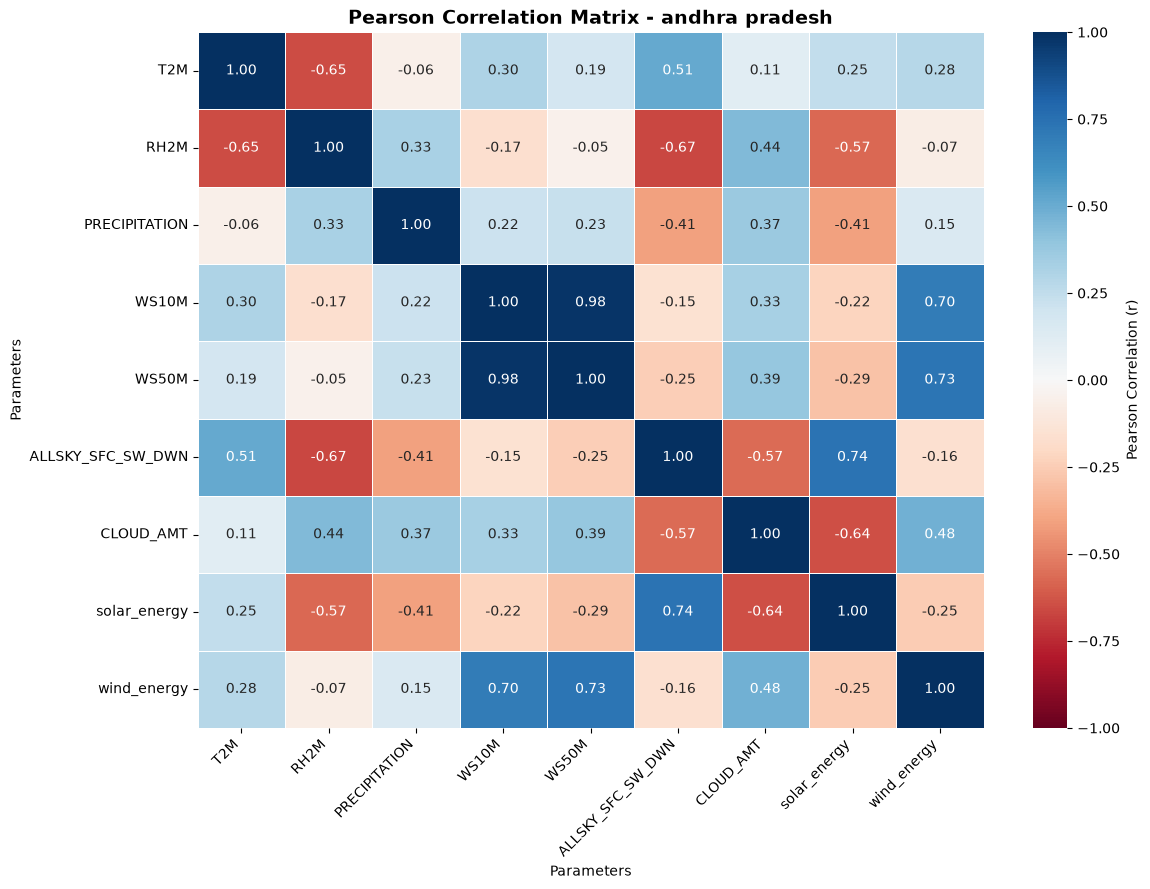

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r"C:\Users\chitt\Downloads\Renewable_Climate_Solar_Wind_Updated.csv"
df = pd.read_csv(file_path)

columns = [
    "T2M", "RH2M", "PRECIPITATION", "WS10M", "WS50M",
    "ALLSKY_SFC_SW_DWN", "CLOUD_AMT",
    "solar_energy", "wind_energy"
]

df[columns] = df[columns].apply(pd.to_numeric, errors="coerce")
df["state_name"] = df["state_name"].astype(str).str.strip()

for state, state_data in df.groupby("state_name"):
    correlation = state_data[columns].corr(method="pearson")

    plt.figure(figsize=(12, 9))
    sns.heatmap(
        correlation, annot=True, fmt=".2f",
        cmap="RdBu", vmin=-1, vmax=1, center=0,
        linewidths=0.5,
        cbar_kws={"label": "Pearson Correlation (r)"}
    )
    plt.title(f"Pearson Correlation Matrix - {state}",
               fontsize=14, fontweight="bold")
    plt.xlabel("Parameters")
    plt.ylabel("Parameters")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

file_path = r"C:\Users\chitt\Downloads\Renewable_Climate_Solar_Wind_Updated.csv"
df = pd.read_csv(file_path)

features = [
    "T2M", "RH2M", "PRECIPITATION", "WS10M",
    "WS50M", "ALLSKY_SFC_SW_DWN", "CLOUD_AMT"
]
for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

X = df[features].dropna()
print("Original dataset rows:", len(df))
print("Rows used for PCA:", len(X))

active_features = [col for col in features if X[col].std() > 0]
X = X[active_features]
if len(X) < 2 or len(active_features) < 2:
    raise ValueError("Insufficient data for PCA")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

variance = pca.explained_variance_ratio_
cumulative = np.cumsum(variance)
pc_names = [f"PC{i+1}" for i in range(len(variance))]

results = pd.DataFrame({
    "Principal Component": pc_names,
    "Explained Variance (%)": variance * 100,
    "Cumulative Variance (%)": cumulative * 100
})
print("\nEXPLAINED VARIANCE:")
print(results.round(4).to_string(index=False))

n_components_95 = np.searchsorted(cumulative, 0.95) + 1
print("\nComponents needed for 95% variance:", n_components_95)

coefficients = pd.DataFrame(
    pca.components_.T, index=active_features, columns=pc_names
)
print("\nPCA COMPONENT COEFFICIENTS:")
print(coefficients.round(4).to_string())

transformed = pd.DataFrame(
    X_pca[:, :n_components_95],
    columns=pc_names[:n_components_95],
    index=X.index
)
print("\nFIRST 10 TRANSFORMED OBSERVATIONS:")
print(transformed.head(10).round(4).to_string())

print("\nPCA SUMMARY")
print("Original features:", len(active_features))
print("Components for 95% variance:", n_components_95)
print("Variance retained (%):",
      round(cumulative[n_components_95 - 1] * 100, 4))

Original dataset rows: 58297
Rows used for PCA: 58297

EXPLAINED VARIANCE:
Principal Component  Explained Variance (%)  Cumulative Variance (%)
                PC1                 32.6156                  32.6156
                PC2                 31.0797                  63.6953
                PC3                 14.7799                  78.4752
                PC4                  8.9114                  87.3866
                PC5                  6.9059                  94.2925
                PC6                  5.2718                  99.5643
                PC7                  0.4357                 100.0000

Components needed for 95% variance: 6

PCA COMPONENT COEFFICIENTS:
                      PC1     PC2     PC3     PC4     PC5     PC6     PC7
T2M               -0.1601  0.3398  0.7441 -0.1193 -0.1893 -0.4967 -0.0922
RH2M               0.5211 -0.0016  0.1400 -0.3740  0.7394 -0.1481 -0.0174
PRECIPITATION      0.4238  0.1954  0.2415  0.8362  0.1028  0.1189 -0.0005
WS10M    

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

file_path = r"C:\Users\chitt\Downloads\Renewable_Climate_Solar_Wind_Updated.csv"
df = pd.read_csv(file_path)

features = [
    "T2M", "RH2M", "PRECIPITATION", "WS10M",
    "WS50M", "ALLSKY_SFC_SW_DWN", "CLOUD_AMT"
]
X = df[features].apply(pd.to_numeric, errors="coerce").dropna()
active_features = [col for col in features if X[col].std() > 0]
X = X[active_features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=6)
X_pca = pca.fit_transform(X_scaled)

pc_names = [f"PC{i+1}" for i in range(6)]

print("Selected components:", pc_names)
print("Variance by component (%):",
      (pca.explained_variance_ratio_ * 100).round(4))
print("Total variance retained (%):",
      round(pca.explained_variance_ratio_.sum() * 100, 4))

coefficients = pd.DataFrame(
    pca.components_.T, index=active_features, columns=pc_names
)
print("\nPC1-PC6 COEFFICIENTS:")
print(coefficients.round(4).to_string())

transformed = pd.DataFrame(
    X_pca, columns=pc_names, index=X.index
)
print("\nFIRST 5 TRANSFORMED OBSERVATIONS:")
print(transformed.head().round(4).to_string())

In [3]:
import numpy as np
import pandas as pd

n_components = pca.n_components_
variance = pca.explained_variance_ratio_

coefficients = pd.DataFrame(
    pca.components_.T,
    index=active_features,
    columns=[f"PC{i+1}" for i in range(n_components)]
)

print("\nDOMINANT FEATURES IN EACH COMPONENT:")
for pc in coefficients.columns:
    ranked = coefficients[pc].abs().sort_values(ascending=False)
    print(f"\n{pc}:")
    for feature in ranked.head(3).index:
        print(feature, "Coefficient:",
              round(coefficients.loc[feature, pc], 4))

importance = np.sum(
    (pca.components_ ** 2) * variance[:, np.newaxis],
    axis=0
)
importance_percent = importance / importance.sum() * 100

feature_ranking = pd.DataFrame({
    "Feature Name": active_features,
    "PCA Contribution (%)": importance_percent
}).sort_values("PCA Contribution (%)", ascending=False)

print("\nOVERALL PCA FEATURE RANKING:")
print(feature_ranking.round(4).to_string(index=False))


DOMINANT FEATURES IN EACH COMPONENT:

PC1:
RH2M Coefficient: 0.5211
ALLSKY_SFC_SW_DWN Coefficient: -0.512
CLOUD_AMT Coefficient: 0.502

PC2:
WS50M Coefficient: 0.6424
WS10M Coefficient: 0.6315
T2M Coefficient: 0.3398

PC3:
T2M Coefficient: 0.7441
ALLSKY_SFC_SW_DWN Coefficient: 0.3977
WS10M Coefficient: -0.3071

PC4:
PRECIPITATION Coefficient: 0.8362
CLOUD_AMT Coefficient: -0.3777
RH2M Coefficient: -0.374

PC5:
RH2M Coefficient: 0.7394
CLOUD_AMT Coefficient: -0.475
ALLSKY_SFC_SW_DWN Coefficient: 0.4096

PC6:
ALLSKY_SFC_SW_DWN Coefficient: 0.6344
CLOUD_AMT Coefficient: 0.5455
T2M Coefficient: -0.4967

PC7:
WS50M Coefficient: 0.7073
WS10M Coefficient: -0.694
T2M Coefficient: -0.0922

OVERALL PCA FEATURE RANKING:
     Feature Name  PCA Contribution (%)
            WS10M               14.2857
            WS50M               14.2857
              T2M               14.2857
        CLOUD_AMT               14.2857
ALLSKY_SFC_SW_DWN               14.2857
    PRECIPITATION               14.2857


lightgbm missing -> skipped
tensorflow missing -> CNN/LSTM skipped
Rows: 58249
Cutoff: 2024-05-07 | train: 46501 | test: 11748
6 PCs retain 99.56% variance

=== solar_energy ===
Multiple Linear Regression   R2=0.1731  RMSE=10.3559
Decision Tree                R2=0.2173  RMSE=10.0751
KNN                          R2=0.2535  RMSE=9.8391
XGBoost                      R2=0.2750  RMSE=9.6968

=== wind_energy ===
Multiple Linear Regression   R2=0.2747  RMSE=12.0646
Decision Tree                R2=0.3158  RMSE=11.7178
KNN                          R2=0.4363  RMSE=10.6359
XGBoost                      R2=0.4586  RMSE=10.4237

=== total_renewable_energy ===
Multiple Linear Regression   R2=0.2619  RMSE=19.7745
Decision Tree                R2=0.3175  RMSE=19.0159
KNN                          R2=0.3836  RMSE=18.0712
XGBoost                      R2=0.4051  RMSE=17.7528

=== solar_energy ===
                     Model     R2    RMSE    MAE  Time(s)
                   XGBoost 0.2750  9.6968 5.8177   2.35

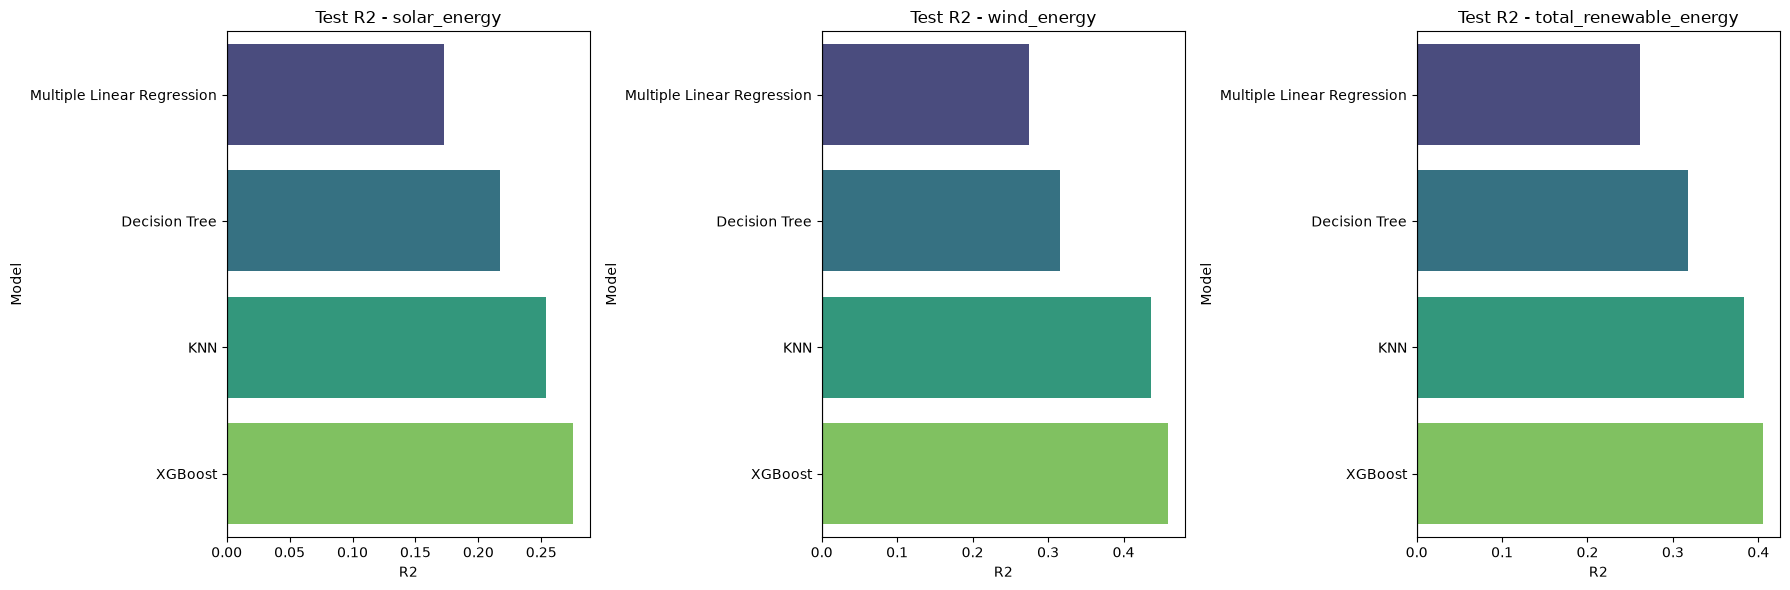

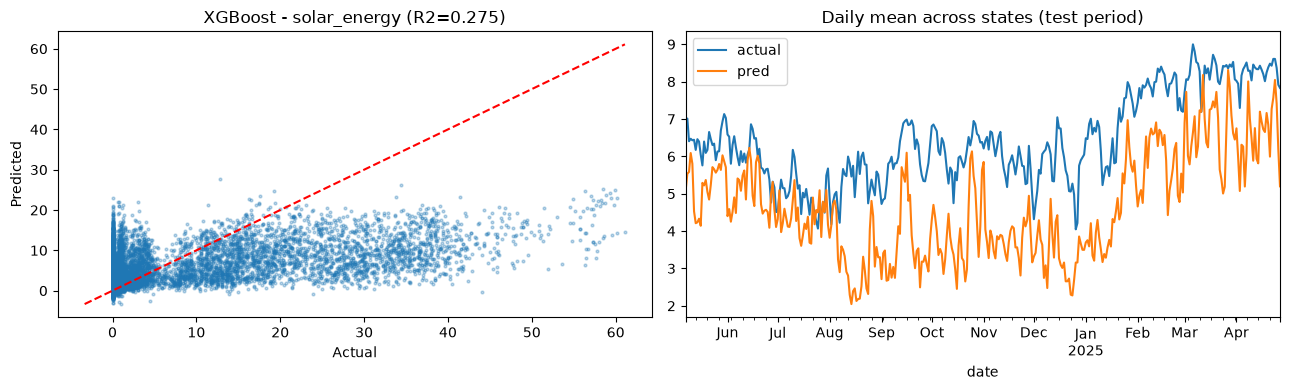

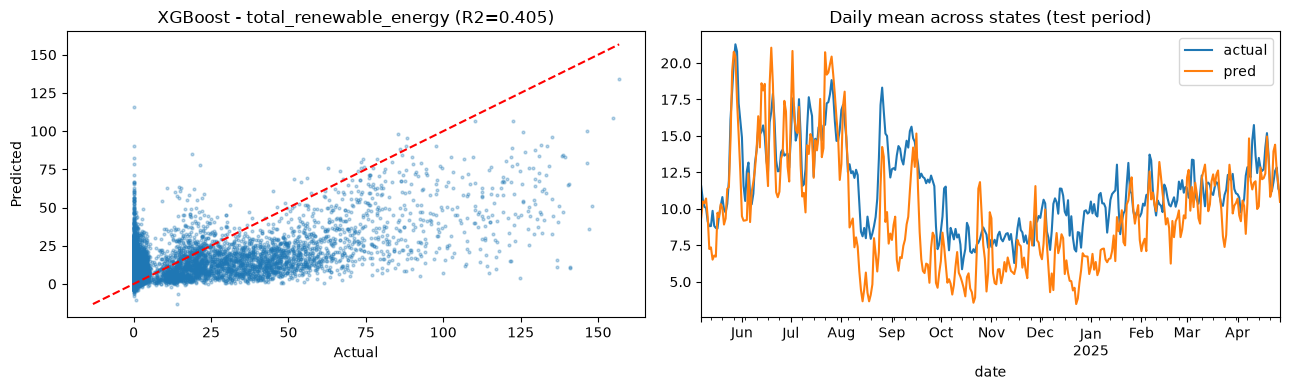

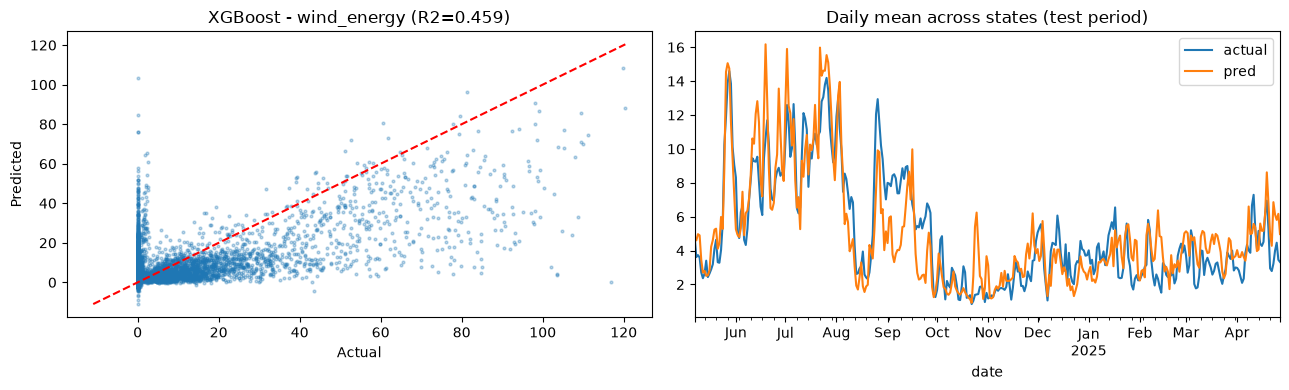

In [2]:
# %% 1. Imports
import warnings, time
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None; print("xgboost missing -> skipped")
try:
    from lightgbm import LGBMRegressor
except ImportError:
    LGBMRegressor = None; print("lightgbm missing -> skipped")
try:
    import tensorflow as tf
    from tensorflow.keras import layers, models, callbacks
    tf.random.set_seed(42)
except ImportError:
    tf = None; print("tensorflow missing -> CNN/LSTM skipped")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# %% 2. Configuration
FILE_PATH = r"C:\Users\chitt\Downloads\Renewable_Climate_Solar_Wind_Updated.csv"
FEATURES = ["T2M", "RH2M", "PRECIPITATION", "WS10M", "WS50M", "ALLSKY_SFC_SW_DWN", "CLOUD_AMT"]
TARGETS  = ["solar_energy", "wind_energy", "total_renewable_energy"]
N_COMPONENTS  = 6
TEST_FRACTION = 0.20
SVR_MAX_ROWS  = 15000
NN_EPOCHS     = 60

# %% 3. Load and clean
df = pd.read_csv(FILE_PATH)
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["state_name"] = df["state_name"].astype(str).str.strip()
for c in FEATURES + TARGETS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df = df.dropna(subset=["date"] + FEATURES + TARGETS).sort_values("date").reset_index(drop=True)
print("Rows:", len(df))

# %% 4. Chronological split
dates = np.sort(df["date"].unique())
cutoff = dates[int(len(dates) * (1 - TEST_FRACTION))]
train_mask = df["date"] < cutoff
test_mask = ~train_mask
print("Cutoff:", pd.Timestamp(cutoff).date(), "| train:", train_mask.sum(), "| test:", test_mask.sum())

# %% 5. Scale + PCA (fit on train only)
scaler = StandardScaler().fit(df.loc[train_mask, FEATURES].values)
Xtr_s = scaler.transform(df.loc[train_mask, FEATURES].values)
Xte_s = scaler.transform(df.loc[test_mask,  FEATURES].values)

pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE).fit(Xtr_s)
Xtr, Xte = pca.transform(Xtr_s), pca.transform(Xte_s)
print(f"{N_COMPONENTS} PCs retain {pca.explained_variance_ratio_.sum()*100:.2f}% variance")

# %% 6. Helpers and models
def metrics(y, p):
    return {"R2": r2_score(y, p),
            "RMSE": np.sqrt(mean_squared_error(y, p)),
            "MAE": mean_absolute_error(y, p)}

def get_models():
    m = {
        "Multiple Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
        "KNN": KNeighborsRegressor(n_neighbors=7, weights="distance", n_jobs=-1),
    }
    if XGBRegressor:
        m["XGBoost"] = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6,
                                    subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=RANDOM_STATE)
    return m

def build_cnn(n):
    mdl = models.Sequential([
        layers.Input(shape=(n, 1)),
        layers.Conv1D(32, 2, activation="relu", padding="same"),
        layers.Conv1D(64, 2, activation="relu", padding="same"),
        layers.MaxPooling1D(2), layers.Flatten(),
        layers.Dense(64, activation="relu"), layers.Dropout(0.2), layers.Dense(1)])
    mdl.compile(optimizer="adam", loss="mse"); return mdl

def build_lstm(n):
    mdl = models.Sequential([
        layers.Input(shape=(n, 1)),
        layers.LSTM(64, return_sequences=True), layers.LSTM(32),
        layers.Dense(32, activation="relu"), layers.Dense(1)])
    mdl.compile(optimizer="adam", loss="mse"); return mdl

def fit_keras(builder, Xtr, ytr_s, Xte):
    mdl = builder(Xtr.shape[1])
    es = callbacks.EarlyStopping(patience=8, restore_best_weights=True)
    mdl.fit(Xtr[..., None], ytr_s, validation_split=0.15, epochs=NN_EPOCHS,
            batch_size=256, callbacks=[es], verbose=0)
    return mdl.predict(Xte[..., None], verbose=0).ravel()

# %% 7. Train and evaluate
results, predictions = [], {}
for target in TARGETS:
    ytr = df.loc[train_mask, target].values
    yte = df.loc[test_mask,  target].values
    print(f"\n=== {target} ===")
    if np.std(ytr) == 0:
        print("constant target -> skipped"); continue

    for name, model in get_models().items():
        t0 = time.time()
        Xf, yf = Xtr, ytr
        if name == "SVR (RBF)" and len(Xtr) > SVR_MAX_ROWS:
            idx = np.random.choice(len(Xtr), SVR_MAX_ROWS, replace=False)
            Xf, yf = Xtr[idx], ytr[idx]
        model.fit(Xf, yf)
        p = model.predict(Xte)
        predictions[(target, name)] = p
        results.append({"Target": target, "Model": name, **metrics(yte, p), "Time(s)": time.time() - t0})
        print(f"{name:28s} R2={results[-1]['R2']:.4f}  RMSE={results[-1]['RMSE']:.4f}")

    if tf is not None:
        ysc = StandardScaler().fit(ytr.reshape(-1, 1))
        ytr_s = ysc.transform(ytr.reshape(-1, 1)).ravel()
        for name, b in [("1D-CNN", build_cnn), ("LSTM", build_lstm)]:
            t0 = time.time()
            p = ysc.inverse_transform(fit_keras(b, Xtr, ytr_s, Xte).reshape(-1, 1)).ravel()
            predictions[(target, name)] = p
            results.append({"Target": target, "Model": name, **metrics(yte, p), "Time(s)": time.time() - t0})
            print(f"{name:28s} R2={results[-1]['R2']:.4f}  RMSE={results[-1]['RMSE']:.4f}")

results_df = pd.DataFrame(results)

# %% 8. Compare results
for target in TARGETS:
    sub = results_df[results_df.Target == target].sort_values("R2", ascending=False)
    if len(sub):
        print(f"\n=== {target} ===")
        print(sub.drop(columns="Target").round(4).to_string(index=False))

best = results_df.loc[results_df.groupby("Target")["R2"].idxmax()]
print("\nBEST MODEL PER TARGET"); print(best.round(4).to_string(index=False))
results_df.to_csv("model_results_after_pca.csv", index=False)

fig, axes = plt.subplots(1, len(TARGETS), figsize=(6 * len(TARGETS), 6))
for ax, target in zip(np.atleast_1d(axes), TARGETS):
    sub = results_df[results_df.Target == target].sort_values("R2")
    if sub.empty: ax.set_visible(False); continue
    sns.barplot(data=sub, x="R2", y="Model", ax=ax, palette="viridis")
    ax.set_title(f"Test R2 - {target}"); ax.axvline(0, c="k", lw=.8)
plt.tight_layout(); plt.show()

# %% 9. Predicted vs actual for best models
for _, row in best.iterrows():
    target, name = row["Target"], row["Model"]
    yte = df.loc[test_mask, target].values
    p = predictions[(target, name)]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].scatter(yte, p, s=4, alpha=.3)
    lim = [min(yte.min(), p.min()), max(yte.max(), p.max())]
    ax[0].plot(lim, lim, "r--"); ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted")
    ax[0].set_title(f"{name} - {target} (R2={row['R2']:.3f})")
    daily = pd.DataFrame({"date": df.loc[test_mask, "date"].values, "actual": yte, "pred": p}).groupby("date").mean()
    daily.plot(ax=ax[1]); ax[1].set_title("Daily mean across states (test period)")
    plt.tight_layout(); plt.show()